<a href="https://colab.research.google.com/github/janhavipatkar854/CSL701-CS42-Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : janhavi patkar

Batch : cs 03


Roll Number : cs 42



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [1]:

# Task 1: Import Libraries and Load Dataset

# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Scikit-learn
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load the Mall Customer Segmentation dataset
df = pd.read_csv('/content/Mall_Customers.csv')

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


First five rows of the dataset:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [2]:

# Task 2: Feature Selection and Standardization

from sklearn.preprocessing import StandardScaler

# Select the required features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected Features:")
display(X.head())

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
)

# Display the first five standardized rows
print("\nStandardized Features:")
display(X_scaled_df.head())

# Verify mean and standard deviation
print("\nMean of Standardized Features:")
print(X_scaled_df.mean())

print("\nStandard Deviation of Standardized Features:")
print(X_scaled_df.std(ddof=0))

# Display the shape
print("\nShape of Standardized Data:", X_scaled.shape)


Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Standardized Features:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Mean of Standardized Features:
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard Deviation of Standardized Features:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64

Shape of Standardized Data: (200, 2)


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

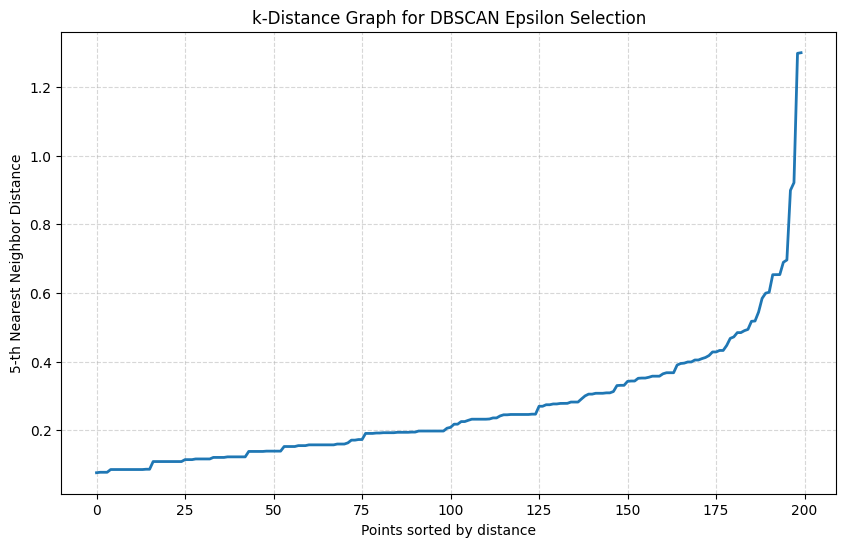

Number of samples: 200
min_samples: 5

Largest k-distances:
[0.602 0.653 0.654 0.654 0.689 0.696 0.899 0.921 1.298 1.3  ]


In [3]:

# Task 3: Hyperparameter Selection via k-Distance Graph

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Set min_samples
min_samples = 5

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

# Find distances and indices of nearest neighbors
distances, indices = neighbors.kneighbors(X_scaled)

# Extract the distance to the k-th nearest neighbor
k_distances = distances[:, min_samples - 1]

# Sort distances in ascending order
k_distances_sorted = np.sort(k_distances)

# Plot the k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(k_distances_sorted, linewidth=2)

plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_samples}-th Nearest Neighbor Distance')
plt.title('k-Distance Graph for DBSCAN Epsilon Selection')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

# Display suggested distance values near the upper end
print("Number of samples:", len(X_scaled))
print("min_samples:", min_samples)
print("\nLargest k-distances:")
print(np.round(k_distances_sorted[-10:], 3))


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [4]:

# Task 4: Implement DBSCAN Clustering

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

# Set parameters based on Task 3
min_samples = 5

# Set epsilon based on the elbow in the Task 3 graph
# Adjust this value after examining your k-distance graph
eps_value = 0.20

# Instantiate and fit DBSCAN
dbscan_model = DBSCAN(
    eps=eps_value,
    min_samples=min_samples
)

# Generate cluster assignments
cluster_labels = dbscan_model.fit_predict(X_scaled)

# Store cluster labels in the original dataset
df['Cluster'] = cluster_labels

# Display cluster assignments
print("First 10 Cluster Assignments:")
print(df[['CustomerID', 'Annual Income (k$)',
          'Spending Score (1-100)', 'Cluster']].head(10))

# Count points in each cluster, including noise (-1)
print("\nCluster Counts (including noise):")
print(df['Cluster'].value_counts().sort_index())

# Calculate number of clusters, excluding noise
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)

# Count noise points
n_noise = np.sum(cluster_labels == -1)

print("\nEpsilon (eps):", eps_value)
print("Min Samples:", min_samples)
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)


First 10 Cluster Assignments:
   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39       -1
1           2                  15                      81        0
2           3                  16                       6       -1
3           4                  16                      77        0
4           5                  17                      40       -1
5           6                  17                      76        0
6           7                  18                       6       -1
7           8                  18                      94       -1
8           9                  19                       3       -1
9          10                  19                      72        0

Cluster Counts (including noise):
Cluster
-1    77
 0     6
 1    78
 2    11
 3     9
 4    10
 5     4
 6     5
Name: count, dtype: int64

Epsilon (eps): 0.2
Min Samples: 5
Number of clusters: 7
Number of noise points: 77


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [5]:

# Task 5: Evaluate DBSCAN Clustering

import numpy as np
from sklearn.metrics import silhouette_score

# Get cluster labels from Task 4
labels = cluster_labels

# 1. Calculate the number of clusters (excluding noise label -1)
unique_labels = set(labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

print("=" * 45)
print("DBSCAN CLUSTERING EVALUATION")
print("=" * 45)

print("\n1. Cluster Count:", n_clusters)

# 2. Analyze noise points
n_noise = np.sum(labels == -1)
total_points = len(labels)
noise_percentage = (n_noise / total_points) * 100

print("\n2. Noise Point Analysis")
print("Total data points:", total_points)
print("Noise points:", n_noise)
print(f"Noise percentage: {noise_percentage:.2f}%")

# Display number of points in each cluster
print("\nPoints per cluster (including noise):")
for label in sorted(unique_labels):
    if label == -1:
        print(f"Noise (-1): {np.sum(labels == -1)} points")
    else:
        print(f"Cluster {label}: {np.sum(labels == label)} points")

# 3. Calculate Silhouette Score
# Ignore noise points when evaluating cluster cohesion/separation
non_noise_mask = labels != -1
non_noise_labels = labels[non_noise_mask]
non_noise_data = X_scaled[non_noise_mask]

print("\n3. Silhouette Score")

if n_clusters >= 2 and len(set(non_noise_labels)) >= 2:
    score = silhouette_score(non_noise_data, non_noise_labels)
    print(f"Silhouette Score (excluding noise): {score:.4f}")
    print("Higher scores generally indicate better-separated clusters.")
else:
    print("Silhouette Score cannot be calculated.")
    print("DBSCAN must produce at least 2 non-noise clusters.")

print("\nEvaluation completed.")


DBSCAN CLUSTERING EVALUATION

1. Cluster Count: 7

2. Noise Point Analysis
Total data points: 200
Noise points: 77
Noise percentage: 38.50%

Points per cluster (including noise):
Noise (-1): 77 points
Cluster 0: 6 points
Cluster 1: 78 points
Cluster 2: 11 points
Cluster 3: 9 points
Cluster 4: 10 points
Cluster 5: 4 points
Cluster 6: 5 points

3. Silhouette Score
Silhouette Score (excluding noise): 0.5856
Higher scores generally indicate better-separated clusters.

Evaluation completed.


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [6]:

# Task 6: Analyze Results and Cluster Statistics

import pandas as pd
import numpy as np

# 1. Append cluster labels to the original dataset
df['Cluster'] = cluster_labels

print("Dataset with Cluster Labels:")
display(df.head(10))

# 2. Calculate cluster statistics
# Include noise (-1) so it can be analyzed separately
cluster_stats = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Annual_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

print("\nCluster Statistics (including noise):")
display(cluster_stats)

# 3. Analyze noise points separately
noise_points = df[df['Cluster'] == -1]

print("\nNoise Point Analysis")
print("Number of noise points:", len(noise_points))

if not noise_points.empty:
    print("\nNoise Point Details:")
    display(noise_points[
        ['CustomerID', 'Age', 'Annual Income (k$)',
         'Spending Score (1-100)', 'Cluster']
    ].head(20))

    print("\nAverage Statistics of Noise Points:")
    display(
        noise_points[
            ['Age', 'Annual Income (k$)',
             'Spending Score (1-100)']
        ].mean().round(2).to_frame(name='Noise Average')
    )
else:
    print("No noise points were identified.")

# 4. Display customer segments excluding noise
regular_clusters = cluster_stats.drop(index=-1, errors='ignore')

print("\nCustomer Segments (excluding noise):")
display(regular_clusters)

# 5. Save the results to a CSV file
df.to_csv('/content/Mall_Customers_with_DBSCAN_Clusters.csv',
          index=False)

print("\nCluster analysis completed.")
print("Dataset saved as Mall_Customers_with_DBSCAN_Clusters.csv")


Dataset with Cluster Labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,-1
1,2,Male,21,15,81,0
2,3,Female,20,16,6,-1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,-1
5,6,Female,22,17,76,0
6,7,Female,35,18,6,-1
7,8,Female,23,18,94,-1
8,9,Male,64,19,3,-1
9,10,Female,30,19,72,0



Cluster Statistics (including noise):


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
-1,77,36.53,61.60,48.53
0,6,23.67,17.83,77.00
1,78,43.13,54.62,50.03
2,11,33.18,74.64,75.18
3,9,38.00,74.44,6.78
4,10,33.10,75.60,91.10
5,4,42.00,78.00,18.75
6,5,49.00,88.60,13.00



Noise Point Analysis
Number of noise points: 77

Noise Point Details:


...


Average Statistics of Noise Points:


,Noise Average
Age,36.53
Annual Income (k$),61.60
Spending Score (1-100),48.53



Customer Segments (excluding noise):


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,6,23.67,17.83,77.00
1,78,43.13,54.62,50.03
2,11,33.18,74.64,75.18
3,9,38.00,74.44,6.78
4,10,33.10,75.60,91.10
5,4,42.00,78.00,18.75
6,5,49.00,88.60,13.00



Cluster analysis completed.
Dataset saved as Mall_Customers_with_DBSCAN_Clusters.csv


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.